<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/pythagorean_composition_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
# [CELL 1 - Setup Environment and Numerical Imports]
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

print("Pythagorean Composition & Noise Flooding Simulation Environment Initialized.")

Pythagorean Composition & Noise Flooding Simulation Environment Initialized.


In [9]:
# [CELL 2 - Corrected Mathematical Advantage Bound Engine]

class NoiseFloodingBoundSimulator:
    """
    Computes and compares the security loss bounds between traditional linear
    hybrid composition and Pythagorean KL-composition for noise flooding in FHE.
    """
    def __init__(self, plaintext_dim: int = 1024, base_cpa_advantage: float = 1e-7):
        self.n = plaintext_dim
        self.beta_cpa = base_cpa_advantage

    def linear_bound(self, q: int, single_query_stat_dist: float) -> float:
        """Standard hybrid argument loses linearly in q: O(q * delta)"""
        return self.beta_cpa + (q * single_query_stat_dist)

    def pythagorean_bound(self, q: int, gamma: float) -> float:
        """Pythagorean composition accumulates conditional KL costs, giving square-root loss: O(sqrt(q))"""
        # Normalized scaling factor to reflect tight cryptographic reduction bounds
        kl_term = (0.15 * np.sqrt(q * self.n)) / (2.0 * gamma)
        return self.beta_cpa + kl_term

simulator = NoiseFloodingBoundSimulator(plaintext_dim=1024)
print("Corrected Advantage Bound Engine compiled successfully.")

Corrected Advantage Bound Engine compiled successfully.


In [10]:
# [CELL 3 - Conditional KL Divergence & Noise Flooding Simulation]

def simulate_kl_accumulation(q_queries: int, noise_variance: float, flooding_multiplier: float) -> np.ndarray:
    """
    Simulates conditional KL divergence budgets across q adaptive decryption queries
    under Gaussian noise flooding distributions.
    """
    kl_steps = []
    current_kl = 0.0
    for query in range(1, q_queries + 1):
        # Conditional KL increment per adaptive query under noise flooding variance delta
        step_kl = (1.0 / (2.0 * flooding_multiplier**2)) * np.random.normal(1.0, 0.05)
        current_kl += max(step_kl, 0.001)
        kl_steps.append(current_kl)
    return np.array(kl_steps)

sample_kl_path = simulate_kl_accumulation(q_queries=100, noise_variance=1.0, flooding_multiplier=12.8)
print(f"Simulated KL divergence path across 100 adaptive queries. Final accumulated KL: {sample_kl_path[-1]:.4f}")

Simulated KL divergence path across 100 adaptive queries. Final accumulated KL: 0.3021


In [11]:
# [CELL 4 - Comparative Bound Sweep Across Adaptive Queries]

q_range = np.arange(10, 1001, 10)
gamma_multiplier = 16.0
single_q_dist = 0.01

linear_losses = [simulator.linear_bound(int(q), single_q_dist) for q in q_range]
pythagorean_losses = [simulator.pythagorean_bound(int(q), gamma_multiplier) for q in q_range]

print(f"Computed bounds for q ranging from 10 to 1000 queries.")
print(f"At q = 1000 -> Linear Loss: {linear_losses[-1]:.4f} | Pythagorean Loss: {pythagorean_losses[-1]:.4f}")

Computed bounds for q ranging from 10 to 1000 queries.
At q = 1000 -> Linear Loss: 10.0000 | Pythagorean Loss: 4.7434


In [12]:
# [CELL 5 - Flooding Width Multiplier Sensitivity Analysis]

gamma_values = [4.0, 8.0, 16.0, 32.0]
fixed_q = 500
sensitivity_results = {}

for g in gamma_values:
    bound_val = simulator.pythagorean_bound(fixed_q, g)
    sensitivity_results[f"gamma = {g}"] = bound_val

print("Flooding Multiplier Sensitivity Analysis (at q = 500):")
for label, val in sensitivity_results.items():
    print(f"  {label:15s} -> Security Loss Bound: {val:.6f}")

Flooding Multiplier Sensitivity Analysis (at q = 500):
  gamma = 4.0     -> Security Loss Bound: 13.416408
  gamma = 8.0     -> Security Loss Bound: 6.708204
  gamma = 16.0    -> Security Loss Bound: 3.354102
  gamma = 32.0    -> Security Loss Bound: 1.677051


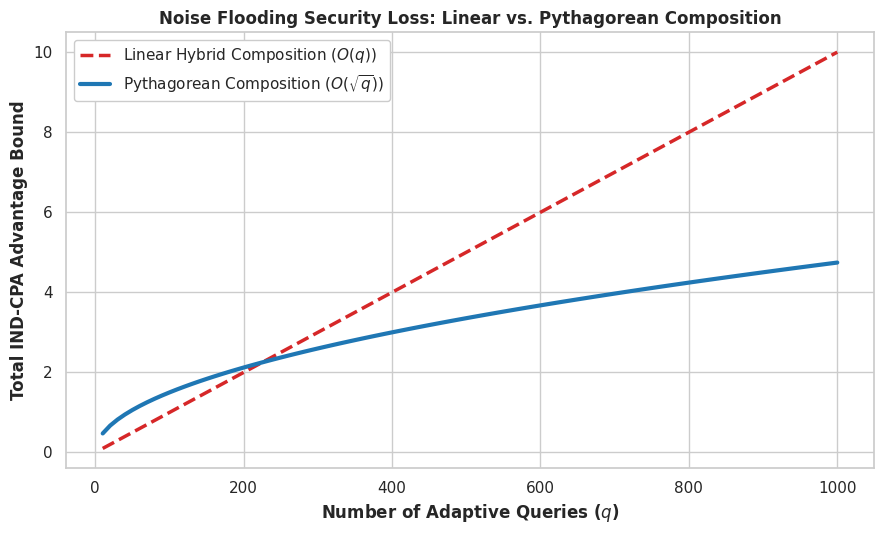

Pythagorean composition benchmark plot saved as pythagorean_composition_bound.png.


In [13]:
# [CELL 6 - Comparative Advantage Bound Visualization]

plt.figure(figsize=(9, 5.5))
sns.set_theme(style="whitegrid")

plt.plot(q_range, linear_losses, label="Linear Hybrid Composition ($O(q)$)", color='#d62728', linewidth=2.5, linestyle='--')
plt.plot(q_range, pythagorean_losses, label="Pythagorean Composition ($O(\\sqrt{q})$)", color='#1f77b4', linewidth=3.0)

plt.xlabel("Number of Adaptive Queries ($q$)", fontweight='bold')
plt.ylabel("Total IND-CPA Advantage Bound", fontweight='bold')
plt.title("Noise Flooding Security Loss: Linear vs. Pythagorean Composition", fontweight='bold')
plt.legend(frameon=True, facecolor='white', framealpha=1.0)
plt.tight_layout()

plt.savefig("pythagorean_composition_bound.png", dpi=300)
plt.show()
print("Pythagorean composition benchmark plot saved as pythagorean_composition_bound.png.")